<a href="https://colab.research.google.com/github/kjm5416-ship-it/secom-anomaly-detection/blob/main/05_%EC%9E%84%EA%B3%84%EA%B0%92%EC%A1%B0%EC%A0%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05. 임계값 조정 — 목표 재현율 0.85 달성

**왜 이 단계가 필요한가.**
04번에서 만든 5종 모델은 기본 설정(확률 0.5 이상이면 불량)으로 채점했더니
재현율이 전부 0.21 이하였다. 전체의 6.6%밖에 없는 불량을
0.5라는 기준으로 거르면 모델이 "거의 다 정상"이라고 답하는 게 유리하기 때문이다.

**이 노트북에서 하는 일.**
1. 지도학습 3종의 교차검증 예측 **확률**을 구한다
2. 재현율 0.85를 넘기는 확률 기준선(임계값)을 **직접 찾는다**
3. 세 모델 중 가장 나은 하나를 고르고, 임계값을 바꿔가며 손익을 표로 정리한다
4. 지금까지 한 번도 안 쓴 **시험 데이터로 딱 한 번** 최종 평가한다
5. 모니터링 화면(STEP 5)에서 쓸 모델·전처리기·임계값을 파일로 저장한다

> 임계값은 코드가 **실행할 때마다 다시 계산**한다. 숫자를 적어 넣지 않았으므로
> 라이브러리 버전이 달라도 그 환경에 맞는 값이 나온다.

## 1. 데이터 불러오기

In [14]:
# ── 구글 드라이브 연결 + 02번에서 저장해 둔 전처리 결과 불러오기 ──
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np

path = '/content/drive/MyDrive/도전학기'
X_train = pd.read_csv(f'{path}/X_train.csv')
y_train = pd.read_csv(f'{path}/y_train.csv').squeeze()
X_test  = pd.read_csv(f'{path}/X_test.csv')
y_test  = pd.read_csv(f'{path}/y_test.csv').squeeze()

RATE = y_train.mean()

print("학습용:", X_train.shape, "| 불량", y_train.sum(), "개")
print("시험용:", X_test.shape, "| 불량", y_test.sum(), "개")
print("불량률: %.4f (%.2f%%)" % (RATE, RATE*100))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
학습용: (1253, 446) | 불량 83 개
시험용: (314, 446) | 불량 21 개
불량률: 0.0662 (6.62%)


## 2. 그래프 한글 폰트

In [15]:
# ── 그래프 한글 폰트 (코랩은 기본으로 한글이 깨진다) ──
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib, matplotlib.pyplot as plt
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf')
plt.rc('font', family='NanumGothic')
plt.rc('axes', unicode_minus=False)
print("한글 폰트 준비 완료")

한글 폰트 준비 완료


## 3. 지도학습 3종의 교차검증 확률 구하기

04번과 똑같은 모델·똑같은 교차검증(5겹)을 쓰되, 이번엔 `predict`(0/1 답)가 아니라
`predict_proba`(불량일 확률)를 받는다. 임계값을 바꿔보려면 확률이 있어야 한다.

이상탐지 2종(Isolation Forest, One-Class SVM)은 확률을 내놓지 않고
04번 결과에서도 PR-AUC가 0.1 근처로 가장 낮았으므로 여기서는 제외한다.

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

모델들 = {
    '로지스틱 회귀': LogisticRegression(max_iter=2000, random_state=42),
    '랜덤 포레스트': RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                      random_state=42, n_jobs=-1),
    'XGBoost':    XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                                scale_pos_weight=(1-RATE)/RATE,
                                eval_metric='logloss', random_state=42, n_jobs=-1),
}

확률 = {}
for 이름, 모델 in 모델들.items():
    확률[이름] = cross_val_predict(모델, X_train, y_train, cv=cv,
                                 method='predict_proba')[:, 1]
    print("%-12s 확률 범위 %.4f ~ %.4f" % (이름, 확률[이름].min(), 확률[이름].max()))

print()
print("※ 최대 확률이 0.5를 못 넘는 모델은 기본 설정으로는 불량을 하나도 못 잡는다.")

로지스틱 회귀      확률 범위 0.0000 ~ 1.0000
랜덤 포레스트      확률 범위 0.0033 ~ 0.2500
XGBoost      확률 범위 0.0000 ~ 0.9033

※ 최대 확률이 0.5를 못 넘는 모델은 기본 설정으로는 불량을 하나도 못 잡는다.


## 4. 임계값 찾기

**규칙:** 재현율이 0.85 이상인 임계값 후보들 중에서 **정밀도가 가장 높은 것**을 고른다.
재현율은 목표이므로 최소 조건으로 걸고, 그 조건을 지키는 선에서 헛알람을 최대한 줄인다는 뜻이다.

`precision_recall_curve`가 가능한 모든 임계값에서의 (정밀도, 재현율) 쌍을 돌려주므로
그중 조건을 만족하는 구간만 추려내면 된다.

In [17]:
from sklearn.metrics import (precision_recall_curve, confusion_matrix,
                             average_precision_score, roc_auc_score)

목표재현율 = 0.85

def 임계값찾기(y, prob, 목표=목표재현율):
    """재현율 >= 목표 를 만족하는 임계값 중 정밀도가 가장 높은 것을 돌려준다."""
    pr, rc, th = precision_recall_curve(y, prob)
    # precision_recall_curve는 pr/rc가 th보다 1개 길다 → 마지막 항목 제외
    pr, rc = pr[:-1], rc[:-1]
    가능 = rc >= 목표
    if not 가능.any():
        return None
    후보 = np.where(가능)[0]
    best = 후보[np.argmax(pr[후보])]
    return float(th[best])

행 = []
임계값 = {}
for 이름, prob in 확률.items():
    t = 임계값찾기(y_train, prob)
    임계값[이름] = t
    pred = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    행.append({
        '방법': 이름,
        '임계값': round(t, 4),
        '잡은 불량': tp, '놓친 불량': fn, '헛알람': fp,
        '재현율': round(tp/(tp+fn), 3),
        '정밀도': round(tp/(tp+fp), 3),
        '검사 대상': tp+fp,
        '검사 비율(%)': round((tp+fp)/len(y_train)*100, 1),
        'PR-AUC': round(average_precision_score(y_train, prob), 3),
    })

임계값표 = pd.DataFrame(행)
pd.set_option('display.width', 220)
임계값표

,방법,임계값,잡은 불량,놓친 불량,헛알람,재현율,정밀도,검사 대상,검사 비율(%),PR-AUC
0,로지스틱 회귀,0.0000,71,12,933,0.855,0.071,1004,80.1,0.123
1,랜덤 포레스트,0.0433,71,12,771,0.855,0.084,842,67.2,0.178
2,XGBoost,0.0005,72,11,844,0.867,0.079,916,73.1,0.150


In [18]:
# 어느 모델을 최종으로 쓸지 — PR-AUC가 가장 높은 것
최종모델명 = 임계값표.loc[임계값표['PR-AUC'].idxmax(), '방법']
최종임계값 = 임계값[최종모델명]

print("선정 모델 :", 최종모델명)
print("선정 임계값: %.4f" % 최종임계값)
print()
print("고른 이유 — 세 모델 모두 재현율 0.85는 넘겼다.")
print("그중 PR-AUC(확률 순위를 얼마나 잘 매기는가)가 가장 높은 모델을 쓴다.")
print("PR-AUC가 높을수록 같은 재현율에서 헛알람이 적다.")

선정 모델 : 랜덤 포레스트
선정 임계값: 0.0433

고른 이유 — 세 모델 모두 재현율 0.85는 넘겼다.
그중 PR-AUC(확률 순위를 얼마나 잘 매기는가)가 가장 높은 모델을 쓴다.
PR-AUC가 높을수록 같은 재현율에서 헛알람이 적다.


## 5. 정밀도–재현율 곡선

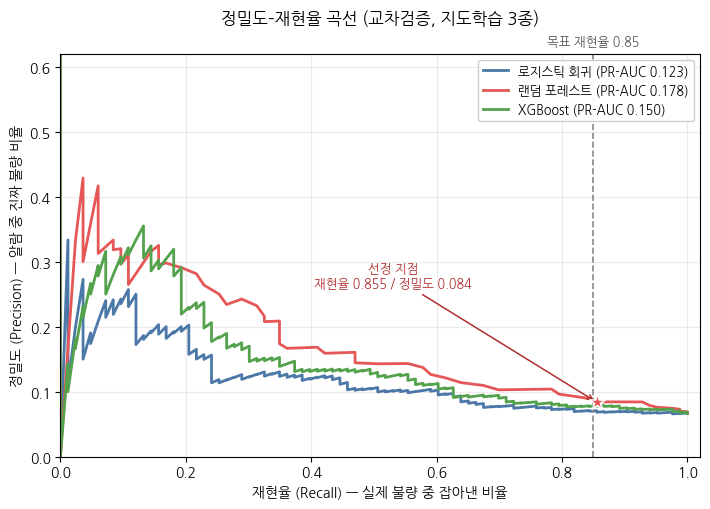

In [19]:
fig, ax = plt.subplots(figsize=(7.2, 5.2))
색 = {'로지스틱 회귀':'#4C78A8', '랜덤 포레스트':'#E45756', 'XGBoost':'#54A24B'}

for 이름, prob in 확률.items():
    pr, rc, _ = precision_recall_curve(y_train, prob)
    ap = average_precision_score(y_train, prob)
    ax.plot(rc, pr, color=색[이름], lw=2, label=f'{이름} (PR-AUC {ap:.3f})')

선정 = 임계값표[임계값표['방법'] == 최종모델명].iloc[0]
ax.scatter([선정['재현율']], [선정['정밀도']], s=140, marker='*',
           color=색[최종모델명], edgecolor='white', zorder=5, linewidth=1.2)
ax.annotate(f"선정 지점\n재현율 {선정['재현율']:.3f} / 정밀도 {선정['정밀도']:.3f}",
            xy=(선정['재현율'], 선정['정밀도']), xytext=(0.52, 0.42),
            textcoords='axes fraction', fontsize=9, color='#B03030', ha='center',
            arrowprops=dict(arrowstyle='->', color='#B03030', lw=1.1))

ax.axvline(목표재현율, color='#888', ls='--', lw=1.2)
ax.text(목표재현율, 1.015, f'목표 재현율 {목표재현율}',
        transform=ax.get_xaxis_transform(), ha='center', va='bottom',
        fontsize=9, color='#555')

ax.set_xlabel('재현율 (Recall) — 실제 불량 중 잡아낸 비율')
ax.set_ylabel('정밀도 (Precision) — 알람 중 진짜 불량 비율')
ax.set_title('정밀도–재현율 곡선 (교차검증, 지도학습 3종)', pad=22, fontsize=12)
ax.set_xlim(0, 1.02)
ax.set_ylim(0, max(0.62, 선정['정밀도']*1.5))
ax.grid(alpha=0.25)
ax.legend(loc='upper right', fontsize=9, framealpha=0.95)
fig.tight_layout()
fig.savefig(f'{path}/그림_PR곡선.png', dpi=160)
plt.show()

## 6. 임계값을 바꾸면 무엇이 달라지는가

재현율과 "검사해야 하는 물량"은 맞바꾸는 관계다.
임계값을 낮추면 불량은 더 많이 잡지만 검사할 웨이퍼가 늘어난다.
현장에서 임계값을 어디에 둘지 정하려면 이 표가 필요하다.

In [20]:
prob최종 = 확률[최종모델명]

후보들 = sorted(set([0.5, 0.3, 0.2, 0.15, 0.12, 0.1,
                    round(최종임계값, 4), 0.07, 0.05]), reverse=True)

행 = []
for t in 후보들:
    pred = (prob최종 >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    행.append({
        '임계값': t,
        '잡은 불량': tp, '놓친 불량': fn, '헛알람': fp,
        '재현율': round(tp/(tp+fn), 3) if (tp+fn) else 0.0,
        '정밀도': round(tp/(tp+fp), 3) if (tp+fp) else 0.0,
        '검사 비율(%)': round((tp+fp)/len(y_train)*100, 1),
    })

민감도표 = pd.DataFrame(행)
print(f"모델: {최종모델명}   /  선정 임계값 {최종임계값:.4f}")
민감도표

모델: 랜덤 포레스트   /  선정 임계값 0.0433


,임계값,잡은 불량,놓친 불량,헛알람,재현율,정밀도,검사 비율(%)
0,0.5000,0,83,0,0.000,0.000,0.0
1,0.3000,0,83,0,0.000,0.000,0.0
2,0.2000,5,78,9,0.060,0.357,1.1
3,0.1500,13,70,31,0.157,0.295,3.5
4,0.1200,26,57,86,0.313,0.232,8.9
5,0.1000,30,53,150,0.361,0.167,14.4
6,0.0700,51,32,370,0.614,0.121,33.6
7,0.0500,68,15,664,0.819,0.093,58.4
8,0.0433,71,12,771,0.855,0.084,67.2


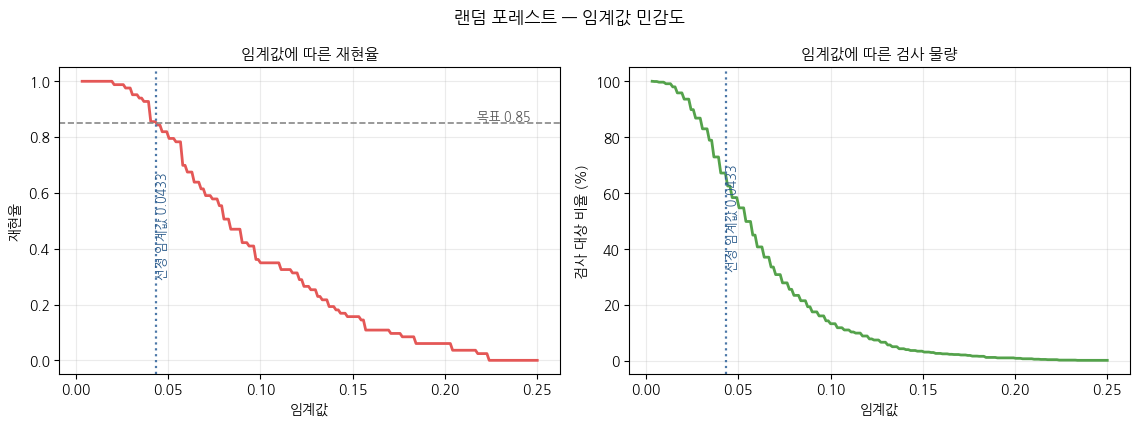

In [21]:
# 임계값을 촘촘하게 훑어서 곡선으로
격자 = np.linspace(prob최종.min(), min(prob최종.max(), 0.5), 200)
재현율선, 검사선 = [], []
for t in 격자:
    pred = (prob최종 >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    재현율선.append(tp/(tp+fn) if (tp+fn) else 0)
    검사선.append((tp+fp)/len(y_train)*100)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))

axes[0].plot(격자, 재현율선, color='#E45756', lw=2)
axes[0].axhline(목표재현율, color='#888', ls='--', lw=1.2)
axes[0].axvline(최종임계값, color='#4C78A8', ls=':', lw=1.6)
axes[0].text(최종임계값, 0.47, f'  선정 임계값 {최종임계값:.4f}',
             fontsize=9, color='#2A5A8A', rotation=90,
             ha='left', va='center')
axes[0].text(격자.max(), 목표재현율, f'목표 {목표재현율}  ', fontsize=9,
             color='#555', ha='right', va='bottom')
axes[0].set_xlabel('임계값')
axes[0].set_ylabel('재현율')
axes[0].set_title('임계값에 따른 재현율', fontsize=11)
axes[0].grid(alpha=0.25)

axes[1].plot(격자, 검사선, color='#54A24B', lw=2)
axes[1].axvline(최종임계값, color='#4C78A8', ls=':', lw=1.6)
axes[1].text(최종임계값, max(검사선)*0.5, f'  선정 임계값 {최종임계값:.4f}',
             fontsize=9, color='#2A5A8A', rotation=90, ha='left', va='center')
axes[1].set_xlabel('임계값')
axes[1].set_ylabel('검사 대상 비율 (%)')
axes[1].set_title('임계값에 따른 검사 물량', fontsize=11)
axes[1].grid(alpha=0.25)

fig.suptitle(f'{최종모델명} — 임계값 민감도', fontsize=12.5)
fig.tight_layout()
fig.savefig(f'{path}/그림_임계값민감도.png', dpi=160)
plt.show()

## 7. 최종 평가 — 시험 데이터 (딱 한 번)

여기까지 임계값은 **학습 데이터의 교차검증 결과만** 보고 정했다.
시험 데이터(X_test)는 02번에서 떼어 둔 뒤 한 번도 건드리지 않았다.
이제 그 데이터로 한 번만 평가한다. 이 숫자가 보고서와 논문에 올라갈 최종 성적이다.

> 시험 데이터를 보고 임계값을 다시 손보면 그 순간 "한 번도 안 본 데이터"가 아니게 된다.
> 그래서 결과가 나빠도 되돌아가서 고치지 않는다.

In [22]:
from sklearn.base import clone

최종모델 = clone(모델들[최종모델명])
최종모델.fit(X_train, y_train)          # 이번엔 학습 데이터 전체로 학습

prob_test = 최종모델.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= 최종임계값).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()

print("=" * 52)
print(f"  최종 결과 — {최종모델명} @ 임계값 {최종임계값:.4f}")
print("=" * 52)
print(f"  전체 시험 웨이퍼     : {len(y_test):>5} 장")
print(f"  그중 실제 불량       : {tp+fn:>5} 장")
print("-" * 52)
print(f"  잡은 불량 (TP)       : {tp:>5}")
print(f"  놓친 불량 (FN)       : {fn:>5}")
print(f"  헛알람   (FP)        : {fp:>5}")
print(f"  정상 통과 (TN)       : {tn:>5}")
print("-" * 52)
print(f"  재현율  Recall       : {tp/(tp+fn):.3f}   ← 목표 {목표재현율}")
print(f"  정밀도  Precision    : {tp/(tp+fp):.3f}")
print(f"  검사 대상            : {tp+fp:>5} 장 ({(tp+fp)/len(y_test)*100:.1f}%)")
print(f"  PR-AUC               : {average_precision_score(y_test, prob_test):.3f}")
print(f"  ROC-AUC              : {roc_auc_score(y_test, prob_test):.3f}")
print("=" * 52)
print()
달성 = tp/(tp+fn) >= 목표재현율
print("목표 재현율 0.85 달성 여부:", "달성" if 달성 else "미달")

  최종 결과 — 랜덤 포레스트 @ 임계값 0.0433
  전체 시험 웨이퍼     :   314 장
  그중 실제 불량       :    21 장
----------------------------------------------------
  잡은 불량 (TP)       :    19
  놓친 불량 (FN)       :     2
  헛알람   (FP)        :   187
  정상 통과 (TN)       :   106
----------------------------------------------------
  재현율  Recall       : 0.905   ← 목표 0.85
  정밀도  Precision    : 0.092
  검사 대상            :   206 장 (65.6%)
  PR-AUC               : 0.170
  ROC-AUC              : 0.733

목표 재현율 0.85 달성 여부: 달성


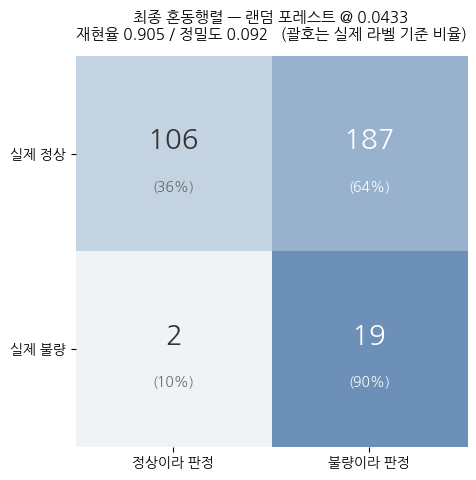

In [23]:
# 혼동행렬 그림
from matplotlib.colors import LinearSegmentedColormap

cm   = np.array([[tn, fp], [fn, tp]])
비율 = cm / cm.sum(axis=1, keepdims=True)      # 행(실제 라벨) 기준 비율로 색칠

fig, ax = plt.subplots(figsize=(5.8, 4.9))
cmap = LinearSegmentedColormap.from_list('b', ['#FFFFFF', '#4C78A8'])
ax.imshow(비율, cmap=cmap, vmin=0, vmax=1, alpha=0.9)

for i in range(2):
    for j in range(2):
        ax.text(j, i - 0.07, f'{cm[i,j]:,}', ha='center', va='center',
                fontsize=20,
                color='white' if 비율[i,j] > 0.55 else '#333')
        ax.text(j, i + 0.17, f'({비율[i,j]*100:.0f}%)', ha='center', va='center',
                fontsize=10,
                color='white' if 비율[i,j] > 0.55 else '#666')

ax.set_xticks([0,1]); ax.set_xticklabels(['정상이라 판정', '불량이라 판정'], fontsize=10)
ax.set_yticks([0,1]); ax.set_yticklabels(['실제 정상', '실제 불량'], fontsize=10)
ax.set_title(f'최종 혼동행렬 — {최종모델명} @ {최종임계값:.4f}\n'
             f'재현율 {tp/(tp+fn):.3f} / 정밀도 {tp/(tp+fp):.3f}'
             '   (괄호는 실제 라벨 기준 비율)',
             fontsize=11, pad=12)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()
fig.savefig(f'{path}/그림_혼동행렬.png', dpi=160)
plt.show()

## 8. 어느 센서가 불량을 가장 잘 알려주는가

모니터링 화면에 590개 센서를 다 띄울 수는 없다.
모델이 판단할 때 실제로 많이 참고한 센서 20개를 뽑아서 화면에 올릴 후보로 쓴다.

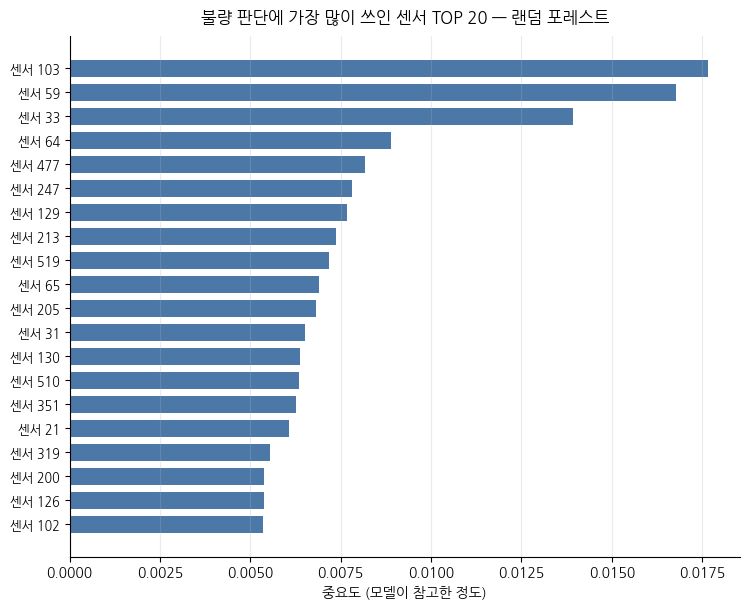

TOP 20 센서 번호: ['103', '59', '33', '64', '477', '247', '129', '213', '519', '65', '205', '31', '130', '510', '351', '21', '319', '200', '126', '102']


In [24]:
if hasattr(최종모델, 'feature_importances_'):
    중요도 = pd.Series(최종모델.feature_importances_, index=X_train.columns)
else:
    중요도 = pd.Series(np.abs(최종모델.coef_[0]), index=X_train.columns)

top20 = 중요도.sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(7.6, 6.2))
ax.barh(range(len(top20))[::-1], top20.values, color='#4C78A8', height=0.72)
ax.set_yticks(range(len(top20))[::-1])
ax.set_yticklabels([f'센서 {c}' for c in top20.index], fontsize=9)
ax.set_xlabel('중요도 (모델이 참고한 정도)')
ax.set_title(f'불량 판단에 가장 많이 쓰인 센서 TOP 20 — {최종모델명}', fontsize=12, pad=10)
ax.grid(axis='x', alpha=0.25)
for s in ['top','right']:
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(f'{path}/그림_중요센서.png', dpi=160)
plt.show()

print("TOP 20 센서 번호:", list(top20.index))

## 9. 저장 — STEP 5 모니터링 화면이 쓸 파일

모니터링 화면은 새 웨이퍼 데이터를 받아 같은 전처리를 거쳐 같은 모델에 넣어야 한다.
그래서 **모델만** 저장하면 안 되고 결측값 채우기(imputer)·표준화(scaler)·임계값·센서 목록까지
한 묶음으로 저장한다.

> 02번에서 imputer와 scaler를 따로 저장해두지 않았다면 아래 셀이
> 02번 전처리를 다시 돌려 그 둘을 만들어 저장한다.

In [25]:
import joblib, os
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# 02번 전처리를 그대로 재현해서 imputer / scaler를 확보한다
url = "https://raw.githubusercontent.com/sharmaroshan/SECOM-Detecting-Defected-Items/master/uci-secom.csv"
df = pd.read_csv(url)
Xa = df.drop(columns=['Time', 'Pass/Fail'])
ya = (df['Pass/Fail'] == 1).astype(int)
Xa = Xa.drop(columns=Xa.columns[Xa.nunique() <= 1])
Xa = Xa.drop(columns=Xa.columns[Xa.isna().mean() > 0.5])

Xa_tr, _, ya_tr, _ = train_test_split(Xa, ya, test_size=0.2,
                                      random_state=42, stratify=ya)
imputer = SimpleImputer(strategy='median').fit(Xa_tr)
scaler  = StandardScaler().fit(imputer.transform(Xa_tr))

번들 = {
    'model':       최종모델,
    'imputer':     imputer,
    'scaler':      scaler,
    'threshold':   float(최종임계값),
    'columns':     list(Xa.columns),
    'top_sensors': list(top20.index),
    'model_name':  최종모델명,
    'metrics': {
        'recall':    float(tp/(tp+fn)),
        'precision': float(tp/(tp+fp)),
        'pr_auc':    float(average_precision_score(y_test, prob_test)),
        'roc_auc':   float(roc_auc_score(y_test, prob_test)),
        'tp': int(tp), 'fn': int(fn), 'fp': int(fp), 'tn': int(tn),
    },
}

joblib.dump(번들, f'{path}/모델_번들.joblib')
민감도표.to_csv(f'{path}/임계값_민감도표.csv', index=False)
임계값표.to_csv(f'{path}/임계값_선정표.csv', index=False)
top20.to_csv(f'{path}/중요센서_TOP20.csv')

print("저장 완료 —", path)
for f in sorted(os.listdir(path)):
    print("  ", f)

저장 완료 — /content/drive/MyDrive/도전학기
   Wafer_모델_번들.joblib
   Wafer_성능비교표.csv
   Wafer_임계값표.csv
   X_test.csv
   X_train.csv
   secom_원본.csv
   y_test.csv
   y_train.csv
   그림
   그림_PR곡선.png
   그림_Wafer파형.png
   그림_데이터셋비교.png
   그림_임계값민감도.png
   그림_중요센서.png
   그림_혼동행렬.png
   두데이터셋_비교.csv
   모델_번들.joblib
   성능비교표_v1.csv
   임계값_민감도표.csv
   임계값_선정표.csv
   중요센서_TOP20.csv


## 정리

| 항목 | 내용 |
|---|---|
| 한 일 | 지도학습 3종의 교차검증 확률로 재현율 0.85 기준선을 찾고, 시험 데이터로 1회 최종 평가 |
| 핵심 발견 | 기본값 0.5는 불량률 6.6% 데이터에 맞지 않는다. 임계값을 내리면 목표 재현율에 도달한다 |
| 맞바꾼 것 | 재현율을 올린 대가로 검사 물량이 늘어난다 (민감도표가 그 손익을 보여준다) |
| 다음 단계 | STEP 4 논문 초안 → STEP 5 모니터링 화면 (`모델_번들.joblib` 사용) |

**깃허브 올리기:** 파일 → GitHub에 사본 저장 → 저장소 `secom-anomaly-detection`,
파일명 `05_임계값조정.ipynb`